# Weather Intelligence · Preprocessing

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Data notebook 3 of 3 · targets, features and splits*

Builds model-ready development (training) and test data for **both** prediction tasks from the raw hourly archive, and saves the fitted preprocessing pipeline that the FastAPI service reuses.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

| Target | Type | Horizon | Output folder |
|:--|:--|:--|:--|
| Climate Comfort Index (CCI) | Regression | +1, +2, +3 days | `data/processed/comfort_climate/` |
| Weather Hazard Category (WHC) | Multiclass classification | exactly +7 days | `data/processed/weather_hazard/` |

**Pipeline:** hourly archive → daily aggregation → CCI and WHI/WHC → one shared, leakage-safe
feature matrix → per-target alignment → chronological splits with an embargo.

**One notebook for both targets.** Both come from the same hourly data at the same location,
aggregated the same way, and are predicted from the same information (everything observed on or
before day *t*). Only the label and horizon differ, so building the features once removes any
risk of the two tasks drifting apart and halves the logic the API must reproduce.

| Step | Shared? | Notes |
|:--|:--|:--|
| Daily aggregation | Shared | Section 1 |
| Feature matrix `X` | Shared | Identical columns for both tasks, section 3 |
| Target `y` | **Differs** | Continuous CCI at *t*+1/2/3 vs hazard class at *t*+7, section 4 |
| Embargo | **Differs** | 3 days for CCI, 7 days for WHC, section 6 |

> **Production parity.** All logic lives in `nucleus_ml.weather`. The preprocessing steps are
> sklearn transformers combined into one `Pipeline`, fitted here and saved to
> `models/preprocessing/`. The API loads that same artefact, and section 7 verifies that a
> serving-sized window reproduces the training features exactly.

---
## 0. Setup

`training_cutoff` makes the pipeline decide which columns never vary using the **training period
only**, even though it is fitted on the full history, so test data cannot influence which features
exist.

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

PATHS = wx.paths()
RAW_CSV = PATHS["raw"] / "sydney_hourly.csv"
DAILY_CSV = PATHS["interim"] / "sydney_daily.csv"
OUTPUT = {task: PATHS["processed"] / task for task in ("comfort_climate", "weather_hazard")}

PIPELINE = wx.build_preprocessing_pipeline(training_cutoff=wx.TEST_START)

print(f"Pipeline : {' -> '.join(name for name, _ in PIPELINE.steps)}")
print(f"Warm-up  : {PIPELINE.warmup_days} days of history per feature row")
print(f"Horizons : CCI {wx.CCI_HORIZONS} days, WHC {wx.WHC_HORIZON} days")
print(f"Splits   : train (development, walk-forward CV) < {wx.TEST_START:%Y-%m-%d} <= test "
      f"< {wx.PRODUCTION_CUTOFF:%Y-%m-%d} (production)")

Pipeline : daily -> features
Warm-up  : 30 days of history per feature row
Horizons : CCI (1, 2, 3) days, WHC 7 days
Splits   : train (development, walk-forward CV) < 2025-01-01 <= test < 2026-01-01 (production)


---
## 1. Daily aggregation

The formulas are written for hourly variables, but both horizons are in days, so the data is
aggregated to **one row per day first** and the formulas are applied once to the daily values.
The targets then describe the daily weather a stakeholder would recognise, and the API can
reproduce them exactly.

| Variable | Rule | Why |
|:--|:--:|:--|
| `temperature_2m`, `relative_humidity_2m`, `wind_speed_10m`, `cloud_cover` | mean | The typical state of the day |
| `precipitation`, `snowfall` | **sum** | Accumulations; the 20 mm and 30 mm constants refer to daily totals |
| `wind_gusts_10m` | **max** | The hazard is the strongest gust of the day; averaging would remove it |

**Daylight saving.** A Sydney calendar day has 23 or 25 hours at the transitions. The aggregator
compares each day with the number of hours that day *actually* had, so transition days count as
complete and only genuinely partial days are masked.

**Masking, not dropping.** Incomplete days become rows of NaN rather than being removed. Removing
them would leave gaps, and because shifts move by position, a gap would silently pair a feature
row with the wrong target date. The warm-up and NaN filters remove masked rows cleanly later.

In [19]:
hourly = wx.load_file(RAW_CSV)
hourly["time"] = wx.to_local_time(hourly["time"])

PIPELINE.fit(hourly)
daily = PIPELINE.daily_frame(hourly)
if not daily.index.equals(pd.date_range(daily.index.min(), daily.index.max(), freq="D")):
    raise ValueError("Daily index has gaps; shifted targets would misalign.")

print(f"Hourly rows : {len(hourly):,} "
      f"({hourly['time'].min():%Y-%m-%d} to {hourly['time'].max():%Y-%m-%d})")
print(f"Daily rows  : {len(daily):,} ({int(daily['cci'].isna().sum())} masked as incomplete)")
print(f"Snowfall present in the extract: {PIPELINE.daily_.snowfall_observed_}")
print(f"Optional predictors found      : {PIPELINE.daily_.optional_columns_ or 'none'}")

hours_per_day = hourly.groupby(hourly["time"].dt.normalize()).size()
print("\nLocal days by number of hours (23 and 25 are daylight-saving days):")
display(hours_per_day.value_counts().sort_index().rename_axis("hours_in_day").to_frame("days"))
daily.head()

Hourly rows : 227,928 (2000-01-01 to 2026-01-01)
Daily rows  : 9,498 (2 masked as incomplete)
Snowfall present in the extract: True
Optional predictors found      : none

Local days by number of hours (23 and 25 are daylight-saving days):


,days
hours_in_day,
11,1
13,1
23,26
24,9444
25,26


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall,temp_score,humidity_score,wind_score,cloud_score,rain_score,cci,rain_hazard,wind_hazard,cloud_hazard,snow_hazard,temp_hazard,whi,whc
date,,,,,,,,,,,,,,,,,,,,
2000-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
2000-01-02,17.471,83.875,10.379,78.917,2.800,34.600,0.000,0.774,0.323,0.991,0.211,0.860,64.444,0.093,0.346,0.789,0.000,0.181,30.775,1
2000-01-03,19.667,75.708,9.200,35.458,0.100,44.600,0.000,0.883,0.486,0.980,0.645,0.995,79.940,0.003,0.446,0.355,0.000,0.093,21.505,0
2000-01-04,22.867,67.875,11.900,54.667,2.200,55.100,0.000,0.957,0.643,0.953,0.453,0.890,80.771,0.073,0.551,0.547,0.000,0.035,30.010,1
2000-01-05,19.275,50.833,12.642,31.958,0.000,47.200,0.000,0.864,0.983,0.934,0.680,1.000,89.114,0.000,0.472,0.320,0.000,0.109,21.642,0


---
## 2. Target construction

Both targets are computed on the daily frame **before** any feature is built. Today's index values
are then legitimate same-day features (section 3), while the values at *t*+h are held back as
labels (section 4).

### 2.1 Climate Comfort Index (regression)

| Score | Formula |
|:--|:--|
| `temp_score` | `max(0, 1 − |temperature_2m − 22| / 20)` |
| `humidity_score` | `max(0, 1 − |relative_humidity_2m − 50| / 50)` |
| `wind_score` | `max(0, 1 − |wind_speed_10m − 10| / 40)` |
| `cloud_score` | `max(0, 1 − cloud_cover / 100)` |
| `rain_score` | `max(0, 1 − precipitation / 20)` |

$$\text{CCI} = 100 \times (0.35\,\text{temp} + 0.20\,\text{humidity} + 0.15\,\text{wind} + 0.15\,\text{cloud} + 0.15\,\text{rain})$$

> **Saturation.** `rain_score` hits zero on any day with 20 mm or more, and `temp_score` beyond
> ±20 °C of 22 °C. Saturation compresses the target range, so its rate is measured below.

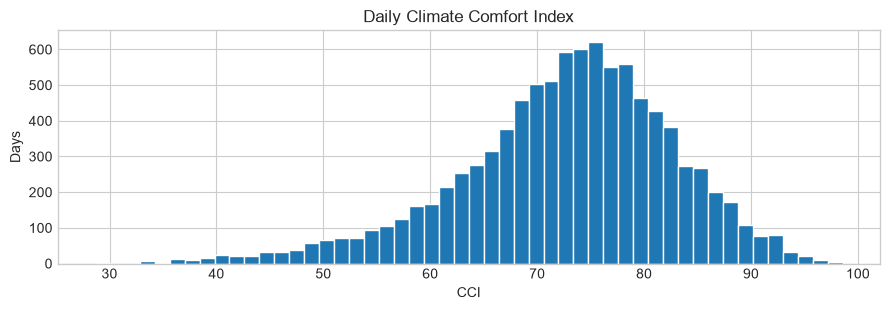

Share of days on which each score is exactly 0 (saturated):


,saturated_share
temp_score,0.000
humidity_score,0.000
wind_score,0.000
cloud_score,0.009
rain_score,0.021


,days,share
cci,,
Very poor (0-19),0,0.000
Poor (20-39),52,0.005
Moderate (40-59),982,0.103
Comfortable (60-79),6277,0.661
Excellent (80-100),2185,0.230


In [20]:
if not daily["cci"].dropna().between(0, 100).all():
    raise ValueError("CCI fell outside the 0-100 range.")

BANDS = ["Very poor (0-19)", "Poor (20-39)", "Moderate (40-59)", "Comfortable (60-79)",
         "Excellent (80-100)"]
bands = pd.cut(daily["cci"], bins=[0, 20, 40, 60, 80, 100.01], right=False, labels=BANDS)
band_table = bands.value_counts(sort=False).to_frame("days")
band_table["share"] = band_table["days"] / band_table["days"].sum()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(daily["cci"].dropna(), bins=50, color="tab:blue", edgecolor="white")
ax.set(title="Daily Climate Comfort Index", xlabel="CCI", ylabel="Days")
fig.tight_layout()
wx.save_figure(fig, "target-cci-distribution", "comfort_climate")
plt.show()

print("Share of days on which each score is exactly 0 (saturated):")
display((daily[wx.CCI_SCORE_COLUMNS].dropna() == 0).mean().round(3).to_frame("saturated_share"))
band_table.round(3)

### 2.2 Weather Hazard Category (classification)

| Hazard | Formula |
|:--|:--|
| `rain_hazard` | `min(precipitation / 30, 1)` |
| `wind_hazard` | `min(wind_gusts_10m / 100, 1)` |
| `cloud_hazard` | `min(cloud_cover / 100, 1)` |
| `snow_hazard` | `min(snowfall / 15, 1)` |
| `temp_hazard` | `min(|temperature_2m − 22| / 25, 1)` |

$$\text{WHI} = 100 \times (0.30\,\text{rain} + 0.30\,\text{wind} + 0.20\,\text{cloud} + 0.10\,\text{snow} + 0.10\,\text{temp})$$

| Condition | Category | Class |
|:--|:--|:-:|
| WHI < 25 | Low Risk | 0 |
| 25 ≤ WHI < 50 | Moderate Risk | 1 |
| 50 ≤ WHI < 75 | High Risk | 2 |
| WHI ≥ 75 | Extreme Risk | 3 |

> **The model is trained on the class, not on WHI.** The continuous `whi` is kept only as a
> same-day feature and as an auxiliary column for error analysis; it is never a predictor of its
> own future value.

**What to expect in Sydney.** Snowfall is zero, gusts rarely approach 100 km/h and the temperature
tolerance is generous, so cloud cover is the only routinely large hazard. The bulk of days should
sit near the Low/Moderate boundary and the upper classes should be rare. This class distribution
decides whether accuracy is meaningful and whether class weighting is needed.

,saturated_share,mean_points_of_whi
rain_hazard,0.010,1.996
wind_hazard,0.000,11.828
cloud_hazard,0.009,9.475
snow_hazard,0.000,0.000
temp_hazard,0.000,2.007


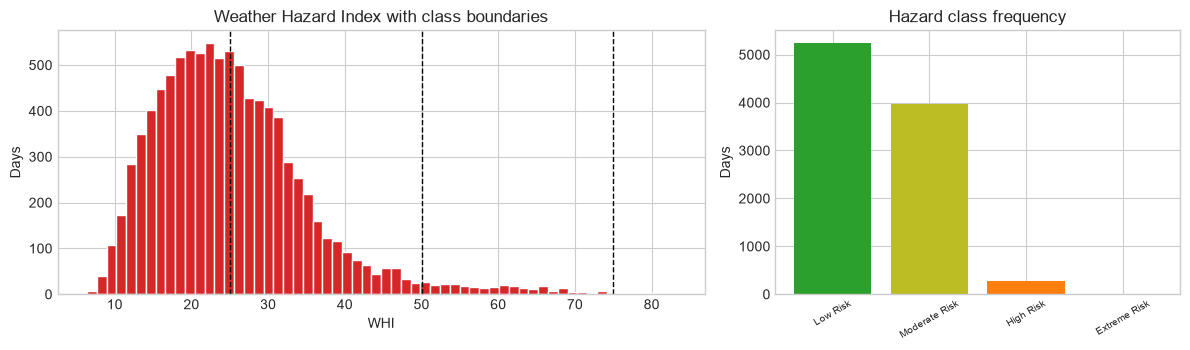

,category,days,share
0,Low Risk,5242,0.552
1,Moderate Risk,3974,0.418
2,High Risk,268,0.028
3,Extreme Risk,12,0.001


In [21]:
if not daily["whi"].dropna().between(0, 100).all():
    raise ValueError("WHI fell outside the 0-100 range.")

WEIGHTS = {"rain_hazard": 0.30, "wind_hazard": 0.30, "cloud_hazard": 0.20,
           "snow_hazard": 0.10, "temp_hazard": 0.10}
hazards = pd.DataFrame({
    "saturated_share": (daily[wx.WHC_HAZARD_COLUMNS].dropna() == 1).mean(),
    "mean_points_of_whi": pd.Series({c: 100 * w * daily[c].mean() for c, w in WEIGHTS.items()}),
})
display(hazards.round(4))

class_counts = daily["whc"].value_counts().reindex(list(wx.WHC_LABELS), fill_value=0)
class_table = pd.DataFrame({"category": pd.Series(wx.WHC_LABELS), "days": class_counts})
class_table["share"] = class_table["days"] / class_table["days"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].hist(daily["whi"].dropna(), bins=60, color="tab:red", edgecolor="white")
for boundary in wx.WHC_BOUNDARIES:
    axes[0].axvline(boundary, color="black", ls="--", lw=1)
axes[0].set(title="Weather Hazard Index with class boundaries", xlabel="WHI", ylabel="Days")
axes[1].bar(class_table["category"], class_table["days"], color=wx.WHC_COLOURS)
axes[1].set(title="Hazard class frequency", ylabel="Days")
axes[1].tick_params(axis="x", labelrotation=30, labelsize=7)
fig.tight_layout()
wx.save_figure(fig, "target-whc-distribution", "weather_hazard")
plt.show()

class_table.round(4)

### 2.3 How related are the two targets?

If CCI and WHI were almost perfectly (negatively) correlated, the hazard classifier would just be
a discretised comfort model. A strong but loose relationship justifies a shared feature matrix
while still warranting separate models; the spread shows the days where they disagree (e.g.
gusty-but-clear days that are hazardous yet pleasant).

CCI vs WHI: Pearson r = -0.716, Spearman rho = -0.619


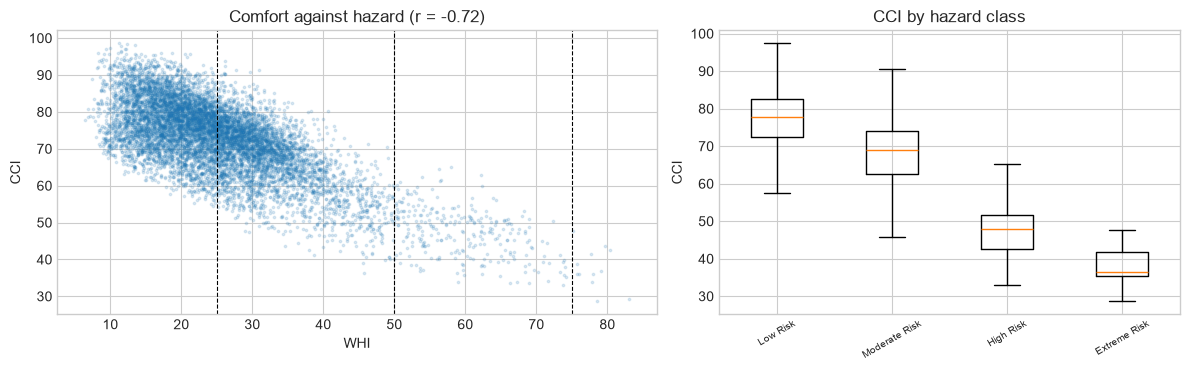

Daily frame saved -> data/interim/sydney_daily.csv


,count,mean,std,min,max
whc,,,,,
0,5242,77.466,7.475,54.407,98.568
1,3974,68.001,8.417,36.405,93.677
2,268,47.470,6.554,33.091,65.144
3,12,37.592,5.613,28.634,47.599


In [22]:
observed = daily.dropna(subset=["cci", "whi"])
pearson = observed["cci"].corr(observed["whi"])
spearman = observed["cci"].corr(observed["whi"], method="spearman")
print(f"CCI vs WHI: Pearson r = {pearson:.3f}, Spearman rho = {spearman:.3f}")

present = [c for c in wx.WHC_LABELS if (observed["whc"] == c).any()]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].scatter(observed["whi"], observed["cci"], s=3, alpha=0.15)
for boundary in wx.WHC_BOUNDARIES:
    axes[0].axvline(boundary, color="black", lw=0.8, ls="--")
axes[0].set(title=f"Comfort against hazard (r = {pearson:.2f})", xlabel="WHI", ylabel="CCI")
axes[1].boxplot([observed.loc[observed["whc"] == c, "cci"] for c in present],
                tick_labels=[wx.WHC_LABELS[c] for c in present], showfliers=False)
axes[1].set(title="CCI by hazard class", ylabel="CCI")
axes[1].tick_params(axis="x", labelrotation=30, labelsize=7)
fig.tight_layout()
wx.save_figure(fig, "targets-cci-vs-whi")
plt.show()

wx.save_file(daily, DAILY_CSV, index_label="date")
print(f"Daily frame saved -> {DAILY_CSV.relative_to(PATHS['root'])}")
observed.groupby("whc")["cci"].agg(["count", "mean", "std", "min", "max"])

---
## 3. Feature engineering (shared)

One feature matrix serves both tasks. Every column uses only observations **on or before** its
date, which makes it valid for any horizon.

| Family | Columns | What it adds |
|:--|:--|:--|
| Same-day observations | Daily value of each variable | Today's weather — the strongest short-range predictor |
| Same-day indices | Five comfort scores + `cci`, hazard scores + `whi` | Distance from the ideal; 12 °C and 32 °C differ as temperatures but score the same |
| Lags | *t*−1, *t*−2, *t*−3, *t*−7 of each variable and index | A short trajectory: end of a cool change vs start of a heatwave |
| Rolling statistics | Mean and std over 3, 7, 14, 30 days | The current regime and how settled it is |
| Rolling precipitation | Rain totals over 3, 7, 14, 30 days | Wet spells and dry regimes |
| Rolling gusts | Maximum gust over 3, 7, 14, 30 days | Recent storminess |
| Deltas | Change over 1 and 3 days | Trends a tree cannot compute itself |
| Seasonal | `doy_sin`, `doy_cos` | Position in the year with no 31 Dec / 1 Jan seam |

> **Leakage rule.** Every column comes from `shift(k)` with `k ≥ 0` or from a rolling window that
> ends on day *t*. `center=True` is never used. Section 7 verifies this empirically.

**Constant columns** are dropped, decided on the training period only. For Sydney this removes
`snowfall` and `snow_hazard`: one of the five hazard terms is inert at this location, so the
effective hazard formula has four contributors.

In [23]:
builder = PIPELINE.features_
FAMILIES = builder.build_families(daily)

print(f"Excluded constant columns: {builder.zero_variance_columns_ or 'none'}")
pd.DataFrame({
    "columns": {name: frame.shape[1] for name, frame in FAMILIES.items()},
    "example": {name: frame.columns[0] for name, frame in FAMILIES.items()},
})

Excluded constant columns: ['snowfall', 'snow_hazard']


,columns,example
same_day_observations,6,temperature_2m
same_day_indices,11,temp_score
lags,32,temperature_2m_lag1
rolling_statistics,40,temperature_2m_roll3_mean
rolling_precipitation,4,precipitation_roll3_sum
rolling_gusts,4,wind_gusts_10m_roll3_max
deltas,6,temperature_2m_delta1
seasonal,2,doy_sin


### 3.1 Same-day observations and indices

Distributions expose skew, zero-inflation and saturation; the series show which variables carry
an annual cycle (the first evidence for the seasonal encoding). In the index panels, look for the
spike at zero in `rain_score` and for how much of `whi` sits near the 25-point boundary.

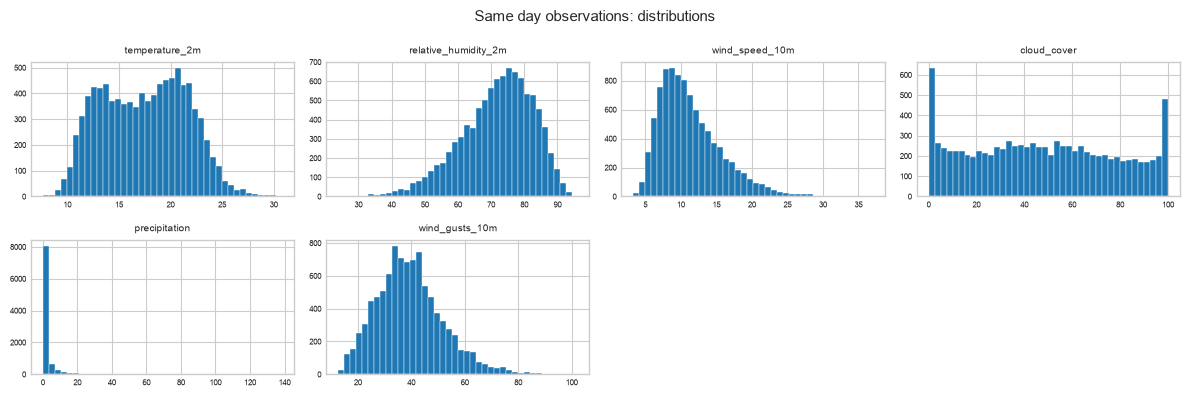

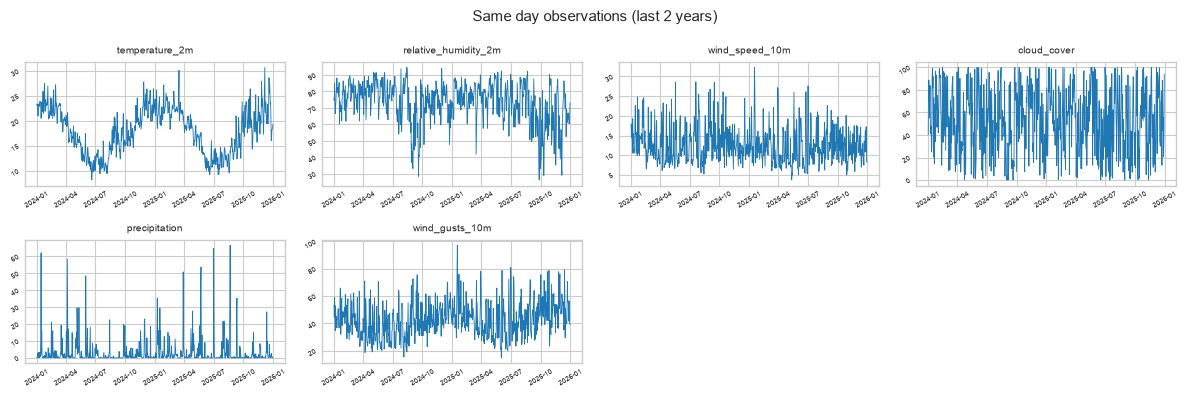

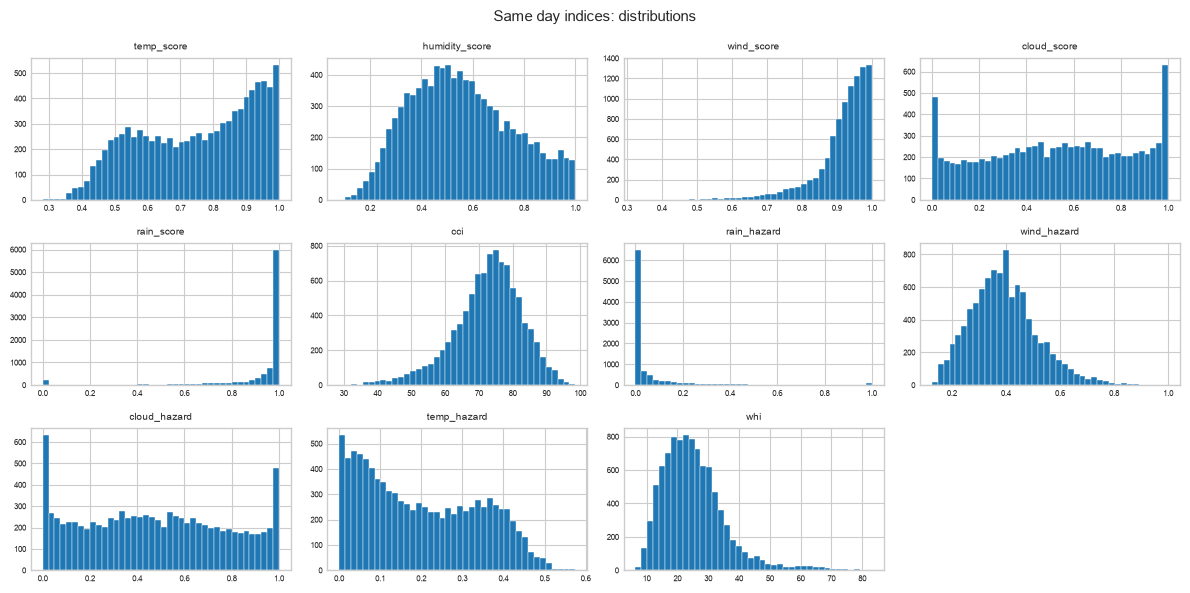

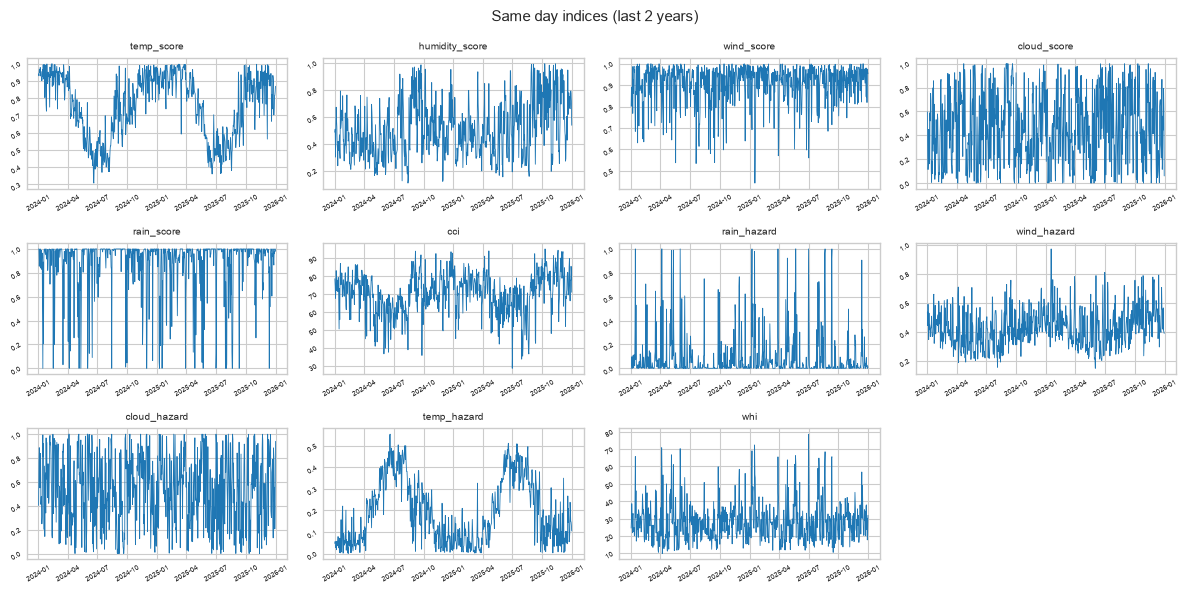

In [24]:
for family in ("same_day_observations", "same_day_indices"):
    label = family.replace("_", " ").capitalize()
    wx.distribution_grid(FAMILIES[family], f"{label}: distributions", f"features-{family}-dist")
    wx.series_grid(FAMILIES[family], label, f"features-{family}-series")
plt.show()

### 3.2 Lags

The informative view of a lag is how its link with today decays. A slow decay means the variable
is persistent and its lags are largely redundant; a fast decay means each lag adds new information.
Read this together with the ablations in the experiment notebooks.

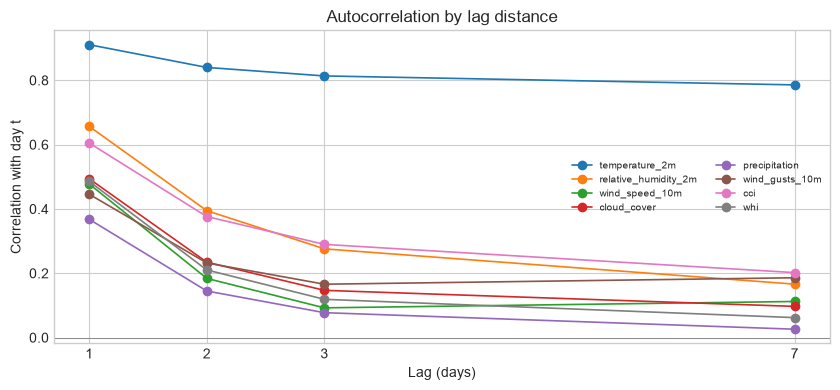

In [25]:
lag_bases = list(dict.fromkeys(c.rsplit("_lag", 1)[0] for c in FAMILIES["lags"]))

fig, ax = plt.subplots(figsize=(8.5, 4))
for column in lag_bases:
    ax.plot(wx.LAG_DAYS, [daily[column].autocorr(lag) for lag in wx.LAG_DAYS],
            marker="o", lw=1.2, label=column)
ax.axhline(0, color="grey", lw=0.6)
ax.set(title="Autocorrelation by lag distance", xlabel="Lag (days)",
       ylabel="Correlation with day t", xticks=list(wx.LAG_DAYS))
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
wx.save_figure(fig, "features-lag-autocorrelation")
plt.show()

### 3.3 Rolling statistics

Longer windows should trace smoother paths, with the 30-day mean acting as a seasonal baseline.
If a long window looks as jagged as the raw series, the smoothing is not working.

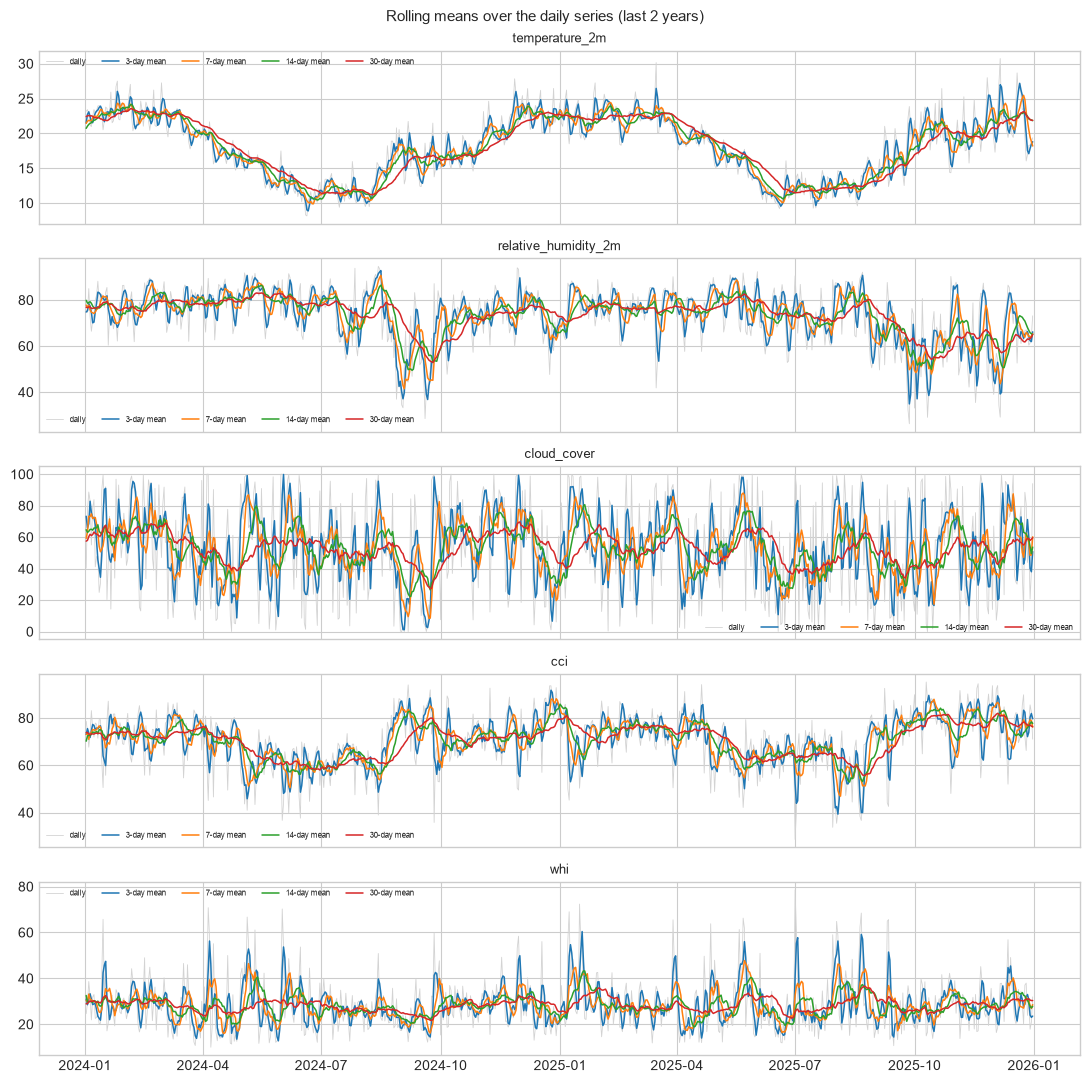

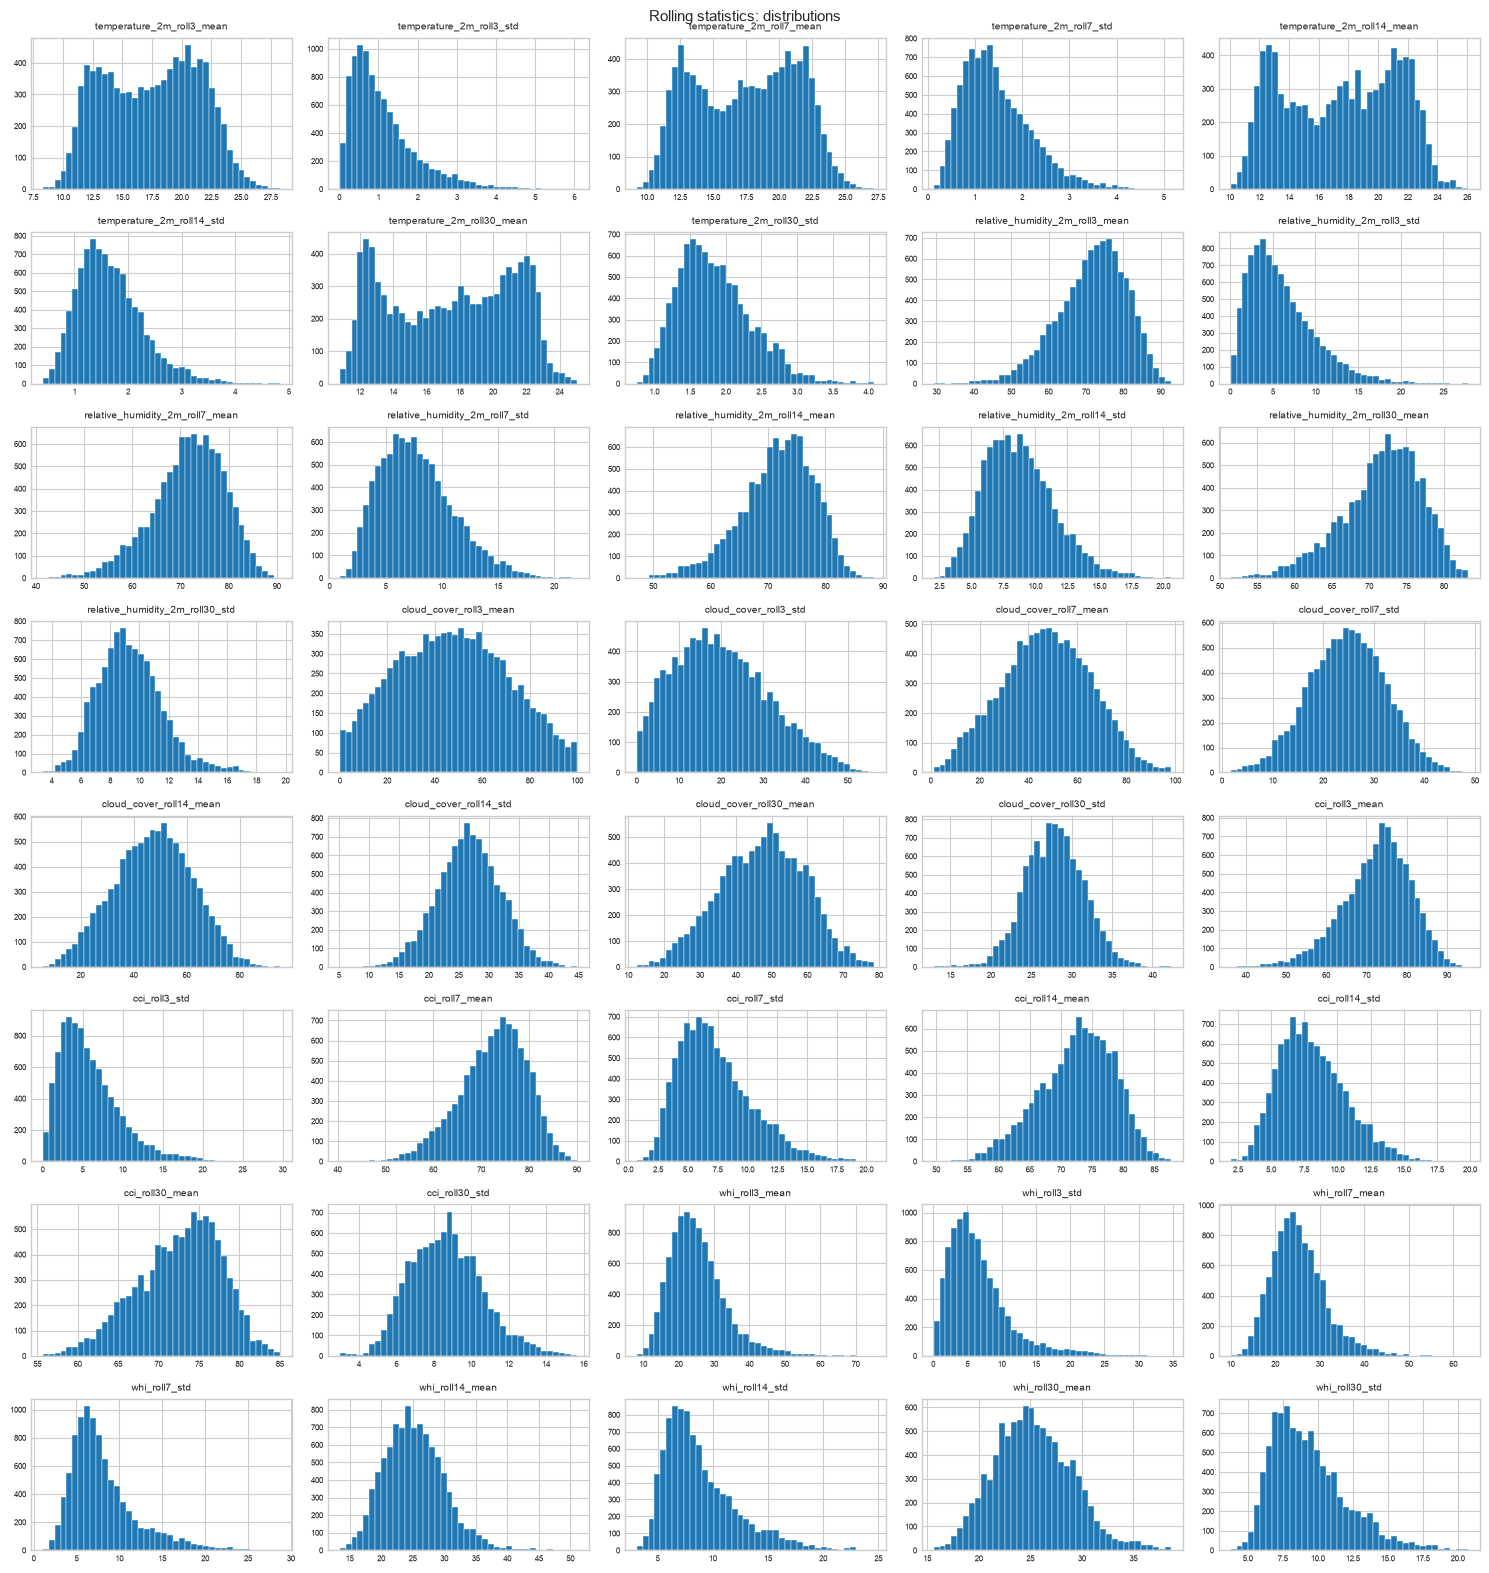

In [26]:
rolling = FAMILIES["rolling_statistics"]
bases = list(dict.fromkeys(c.split("_roll")[0] for c in rolling))
recent = daily.index[daily.index > daily.index.max() - pd.DateOffset(years=2)]

fig, axes = plt.subplots(len(bases), 1, figsize=(11, 2.2 * len(bases)), sharex=True)
for ax, column in zip(np.atleast_1d(axes), bases):
    ax.plot(recent, daily.loc[recent, column], color="lightgrey", lw=0.6, label="daily")
    for window in wx.ROLLING_WINDOWS:
        ax.plot(recent, rolling.loc[recent, f"{column}_roll{window}_mean"], lw=1.1,
                label=f"{window}-day mean")
    ax.set_title(column, fontsize=9)
    ax.legend(fontsize=6, ncol=5)
fig.suptitle("Rolling means over the daily series (last 2 years)", fontsize=11)
fig.tight_layout()
wx.save_figure(fig, "features-rolling-means")
plt.show()

wx.distribution_grid(rolling, "Rolling statistics: distributions", "features-rolling-dist",
                     ncols=5)
plt.show()

### 3.4 Rolling precipitation and gusts

Rainfall totals are heavily right-skewed, so they use a log count axis. Gust maxima should form
plateaus: one storm sets the maximum, which holds until it leaves the window. The red line marks
where `wind_hazard` saturates (100 km/h).

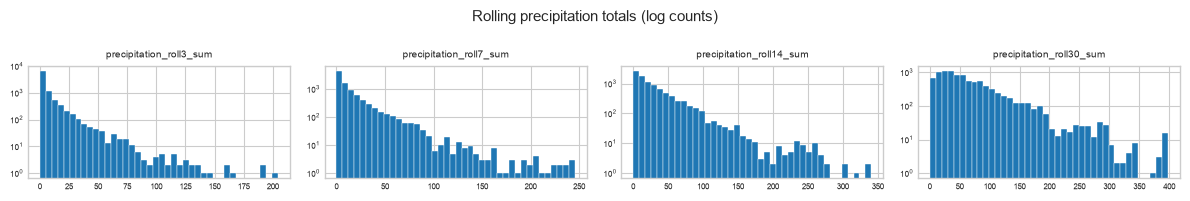

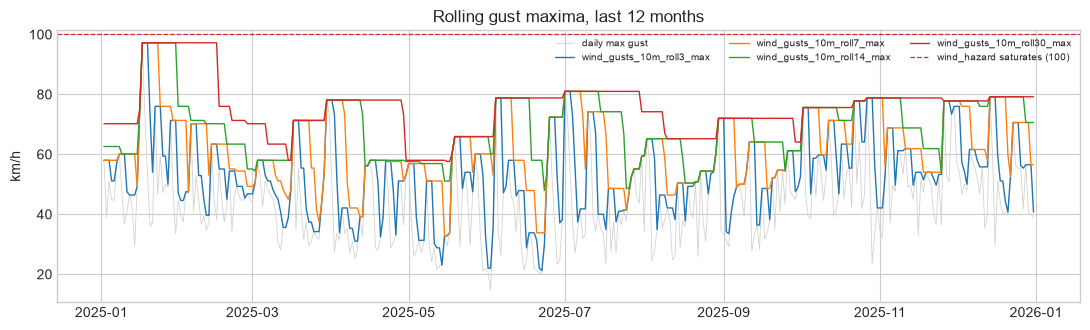

In [27]:
wx.distribution_grid(FAMILIES["rolling_precipitation"], "Rolling precipitation totals (log counts)",
                     "features-rolling-precipitation-dist", log_counts=True)

gusts = FAMILIES["rolling_gusts"]
last_year = gusts.index[gusts.index > gusts.index.max() - pd.DateOffset(years=1)]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(last_year, daily.loc[last_year, "wind_gusts_10m"], color="lightgrey", lw=0.6,
        label="daily max gust")
for column in gusts.columns:
    ax.plot(last_year, gusts.loc[last_year, column], lw=1.0, label=column)
ax.axhline(100, color="tab:red", ls="--", lw=0.9, label="wind_hazard saturates (100)")
ax.set(title="Rolling gust maxima, last 12 months", ylabel="km/h")
ax.legend(fontsize=7, ncol=3)
fig.tight_layout()
wx.save_figure(fig, "features-rolling-gusts")
plt.show()

### 3.5 Deltas and seasonal position

Deltas should be centred on zero. Their tails are the interesting part: large negative
`temperature_2m_delta1` values are Sydney's southerly busters, the abrupt changes persistence
cannot anticipate.

The seasonal encoding is justified only if the targets vary through the year. The profiles below
show mean CCI and WHI by day of year and the hazard class mix by month; flat curves would make the
two seasonal columns dead weight.

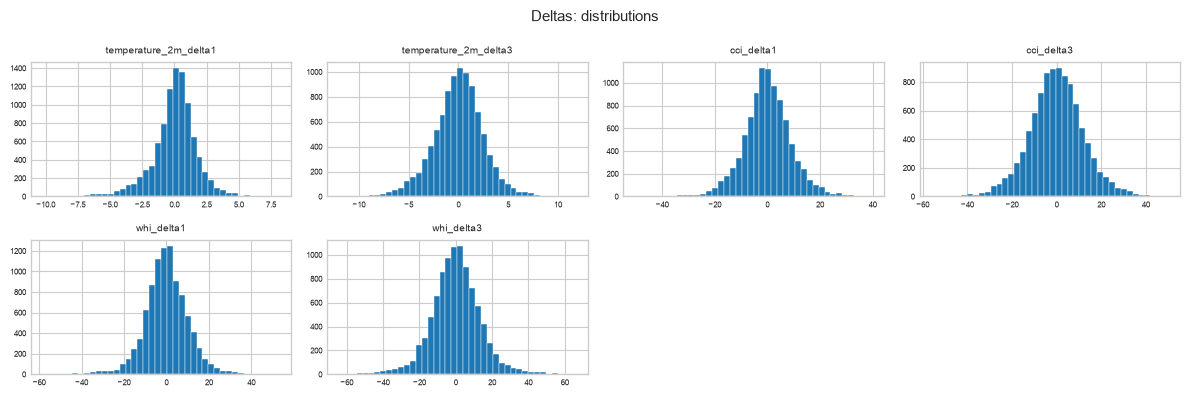

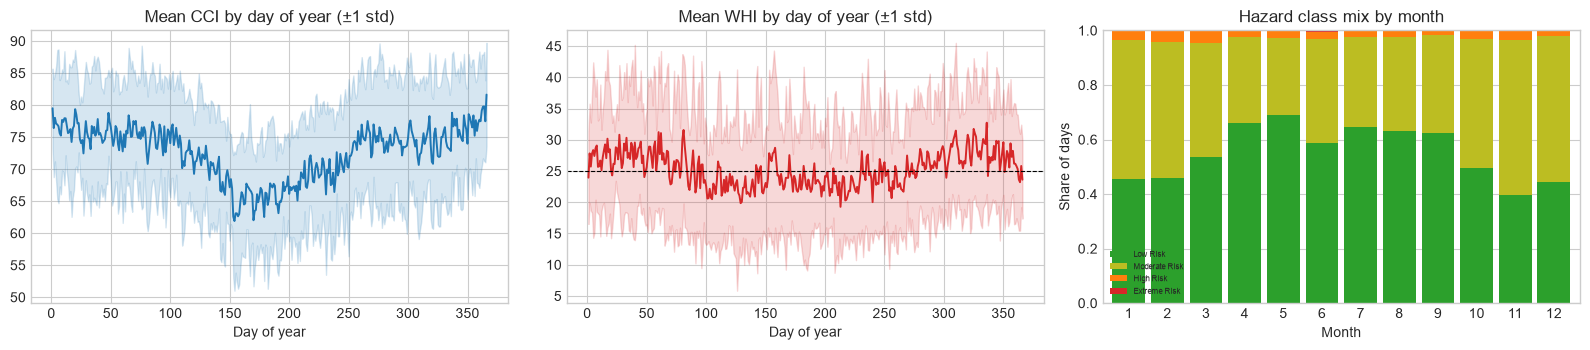

In [28]:
wx.distribution_grid(FAMILIES["deltas"], "Deltas: distributions", "features-deltas-dist")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, (column, colour) in zip(axes[:2], [("cci", "tab:blue"), ("whi", "tab:red")]):
    profile = daily.groupby(daily.index.dayofyear)[column].agg(["mean", "std"])
    ax.fill_between(profile.index, profile["mean"] - profile["std"],
                    profile["mean"] + profile["std"], color=colour, alpha=0.18)
    ax.plot(profile.index, profile["mean"], color=colour, lw=1.4)
    ax.set(title=f"Mean {column.upper()} by day of year (±1 std)", xlabel="Day of year")
axes[1].axhline(25, color="black", lw=0.8, ls="--")

class_mix = pd.crosstab(daily.index.month, daily["whc"], normalize="index")
class_mix.rename(columns=wx.WHC_LABELS).plot.bar(
    stacked=True, ax=axes[2], width=0.85, color=wx.WHC_COLOURS[:class_mix.shape[1]])
axes[2].set(title="Hazard class mix by month", xlabel="Month", ylabel="Share of days")
axes[2].legend(fontsize=6)
axes[2].tick_params(labelrotation=0)
fig.tight_layout()
wx.save_figure(fig, "features-seasonal-profiles")
plt.show()

### 3.6 The complete feature matrix

One `transform` call produces the whole matrix — the same call the API makes. The completeness
chart shows how many rows each family loses to its warm-up (the 30-day windows are the binding
constraint). The correlation heatmap, blocked by family, reveals redundancy: correlated features
share importance in the models and can each look unimportant alone.

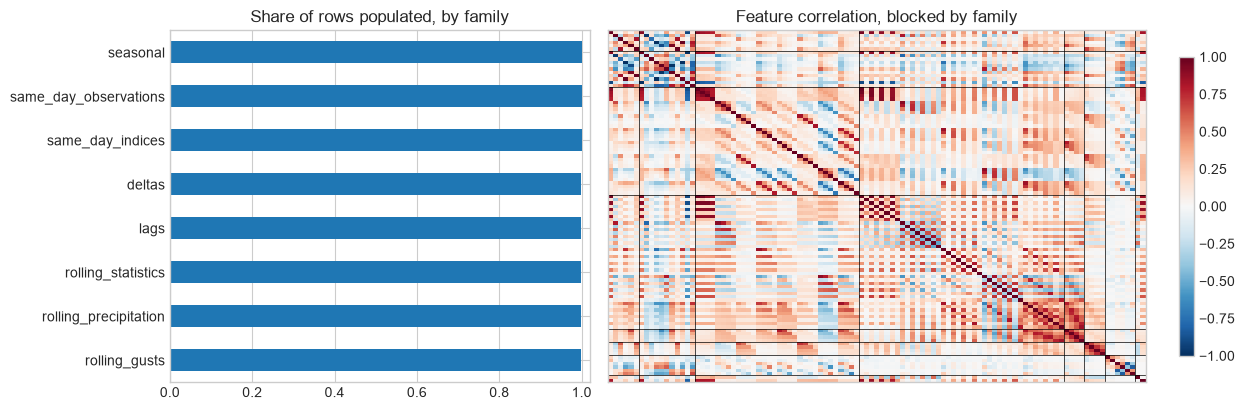

105 shared features across 8 families


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m
date,,,,,,
2025-12-30,18.738,64.083,8.442,37.917,0.000,40.000
2025-12-31,19.375,73.125,8.138,94.000,0.400,38.900
2026-01-01,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
features = PIPELINE.transform(hourly)
FEATURE_COLUMNS = list(features.columns)
FEATURE_GROUPS = builder.feature_groups_
family = pd.Index(FEATURE_COLUMNS).map(builder.family_of)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
features.notna().mean().groupby(family).mean().sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Share of rows populated, by family", xlim=(0, 1.02))
image = axes[1].imshow(features.corr(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
edge = 0
for columns in FEATURE_GROUPS.values():
    edge += len(columns)
    axes[1].axhline(edge - 0.5, color="black", lw=0.5)
    axes[1].axvline(edge - 0.5, color="black", lw=0.5)
axes[1].set(title="Feature correlation, blocked by family", xticks=[], yticks=[])
fig.colorbar(image, ax=axes[1], shrink=0.85)
fig.tight_layout()
wx.save_figure(fig, "features-matrix-overview")
plt.show()

print(f"{len(FEATURE_COLUMNS)} shared features across {len(FEATURE_GROUPS)} families")
features.tail(3).iloc[:, :6]

---
## 4. Target alignment

The features are shared; the labels are not. `wx.future_values` shifts each index backwards by
its horizon, so every row pairs day *t*'s features with the value observed *h* days later.

| Block | Columns | Meaning |
|:--|:--|:--|
| Comfort | `cci_t1`, `cci_t2`, `cci_t3` | CCI observed on *t*+1, *t*+2, *t*+3 |
| Hazard | `whc_t7` | Hazard class on *t*+7 — **the model target** |
| Hazard (auxiliary) | `whi_t7` | The WHI behind `whc_t7`, for error analysis only |

> **`whi_t7` is never a feature.** It is the label in continuous form and is written to a separate
> `aux_*.csv` file. Using it as a predictor would be direct leakage.

Alignment is verified **by value**: every target is compared with the index looked up at
`date + horizon`, which would catch a shift landing on the wrong row. Rows are then dropped for an
incomplete warm-up, missing values, or a target date in the reserved 2026 period.

In [30]:
cci_targets = wx.future_values(daily, ["cci"], wx.CCI_HORIZONS)
whc_targets = wx.future_values(daily, ["whc", "whi"], [wx.WHC_HORIZON])
wx.verify_future_values(cci_targets, daily)
wx.verify_future_values(whc_targets, daily)

CCI_TARGETS = list(cci_targets.columns)
WHC_TARGET, WHC_AUX = f"whc_t{wx.WHC_HORIZON}", f"whi_t{wx.WHC_HORIZON}"

cci_dataset = wx.assemble_dataset(features, cci_targets, wx.CCI_EMBARGO, label="Comfort (CCI)")
whc_dataset = wx.assemble_dataset(features, whc_targets, wx.WHC_HORIZON, label="Hazard (WHC)")
whc_dataset[WHC_TARGET] = whc_dataset[WHC_TARGET].astype(int)

pd.concat([daily[["cci", "whc"]], cci_targets, whc_targets[[WHC_TARGET]]], axis=1).head(9)

Alignment verified for ['cci_t1', 'cci_t2', 'cci_t3'].
Alignment verified for ['whc_t7', 'whi_t7'].
Comfort (CCI): 9,464 rows (2000-01-31 to 2025-12-28); 4 incomplete rows dropped; latest target 2025-12-31
Hazard (WHC): 9,460 rows (2000-01-31 to 2025-12-24); 8 incomplete rows dropped; latest target 2025-12-31


,cci,whc,cci_t1,cci_t2,cci_t3,whc_t7
date,,,,,,
2000-01-01,NaN,<NA>,64.444,79.940,80.771,1
2000-01-02,64.444,1,79.940,80.771,89.114,1
2000-01-03,79.940,0,80.771,89.114,82.761,1
2000-01-04,80.771,1,89.114,82.761,74.349,1
2000-01-05,89.114,0,82.761,74.349,70.836,1
2000-01-06,82.761,0,74.349,70.836,73.595,1
2000-01-07,74.349,1,70.836,73.595,76.045,0
2000-01-08,70.836,1,73.595,76.045,72.301,0
2000-01-09,73.595,1,76.045,72.301,74.616,1


---
## 5. Feature strength against each target

A descriptive screen of which features relate to each target. It is run for **documentation
only** and is never used to select columns, because it includes the test period.

- **Comfort:** Pearson correlation with each horizon. Features that hold their correlation at
  *t*+3 carry genuine forecast signal rather than persistence.
- **Hazard:** correlation suits a numeric target, not ordered categories, so **eta squared (η²)**
  is used: the share of a feature's variance that lies *between* hazard classes (0 = no
  separation, 1 = perfect separation).

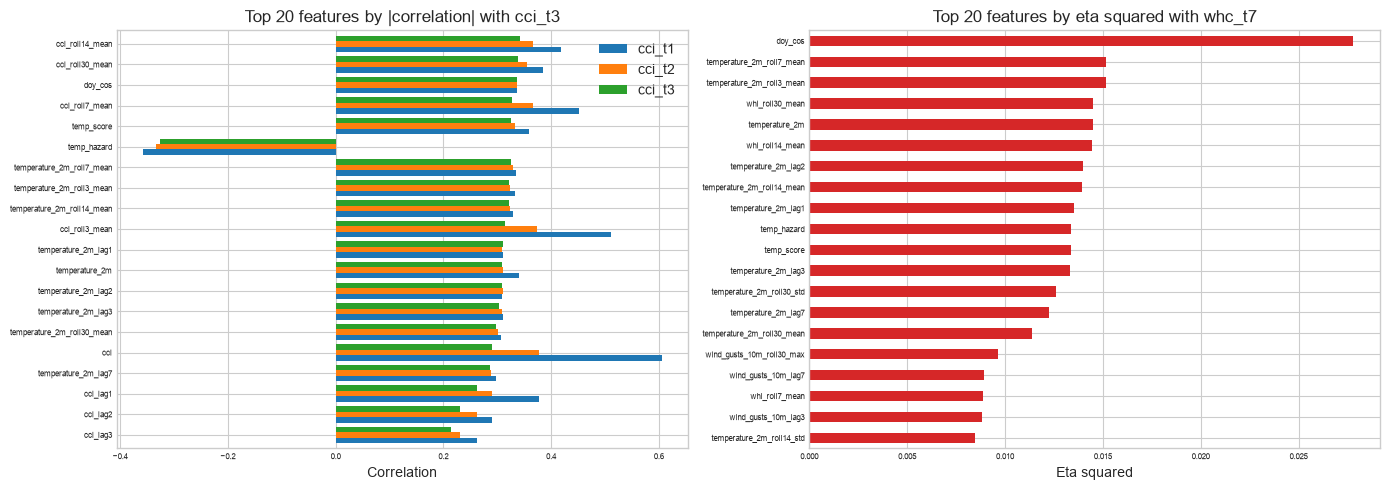

,mean_abs_corr_cci_t1,mean_abs_corr_cci_t3,mean_eta_sq_whc_t7
seasonal,0.174,0.169,0.016
same_day_indices,0.315,0.137,0.004
rolling_statistics,0.165,0.112,0.004
same_day_observations,0.236,0.110,0.004
lags,0.124,0.098,0.004
rolling_precipitation,0.142,0.058,0.002
rolling_gusts,0.053,0.052,0.007
deltas,0.179,0.030,0.000


In [31]:
cci_correlation = pd.DataFrame({t: cci_dataset[FEATURE_COLUMNS].corrwith(cci_dataset[t])
                                for t in CCI_TARGETS})
whc_strength = wx.eta_squared(whc_dataset, FEATURE_COLUMNS, WHC_TARGET)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_cci = cci_correlation["cci_t3"].abs().nlargest(20).index
cci_correlation.loc[top_cci].iloc[::-1].plot.barh(ax=axes[0], width=0.8)
axes[0].set(title="Top 20 features by |correlation| with cci_t3", xlabel="Correlation")
whc_strength.head(20).iloc[::-1].plot.barh(ax=axes[1], color="tab:red")
axes[1].set(title=f"Top 20 features by eta squared with {WHC_TARGET}", xlabel="Eta squared")
for ax in axes:
    ax.tick_params(labelsize=6)
fig.tight_layout()
wx.save_figure(fig, "features-target-strength")
plt.show()

pd.DataFrame({
    "mean_abs_corr_cci_t1": cci_correlation["cci_t1"].abs().groupby(family).mean(),
    "mean_abs_corr_cci_t3": cci_correlation["cci_t3"].abs().groupby(family).mean(),
    "mean_eta_sq_whc_t7": whc_strength.reindex(FEATURE_COLUMNS).groupby(family).mean(),
}).sort_values("mean_abs_corr_cci_t3", ascending=False)

---
## 6. Chronological splits with an embargo

Splits follow the calendar and are never shuffled: consecutive days are strongly correlated, so a
random split would leak the future into training.

| Split | Period |
|:--|:--|
| Train (development) | Start of the archive to the end of 2024 |
| Test | 2025 |
| Production (excluded) | 2026 onwards |

There is **no separate validation split**. Model selection uses walk-forward cross-validation
inside the development split: four expanding-window folds that validate on 2021, 2022, 2023 and
2024 in turn. A single validation year is noisy; four years make every decision more reliable,
and 2024 is still used for training the final model.

An **embargo** equal to the horizon (3 days for CCI, 7 for WHC) is removed before the test
boundary, and the same gap separates training and validation inside every fold; otherwise the
last training rows would carry targets dated inside the held-out period.

> Scaling and imputation are deliberately **not** done here. They must be fitted on training data
> only, so they live inside the model pipelines in the experiment notebooks.

A chronological split cannot be stratified, so the class mix per split is whatever the weather
delivered. The class table below is a required check: a class missing from a split makes its
per-class metrics undefined.

Comfort (CCI):


,rows,start,end,last_target
train,9099,2000-01-31,2024-12-28,2024-12-31
test,362,2025-01-01,2025-12-28,2025-12-31


Hazard (WHC):


,rows,start,end,last_target
train,9095,2000-01-31,2024-12-24,2024-12-31
test,358,2025-01-01,2025-12-24,2025-12-31


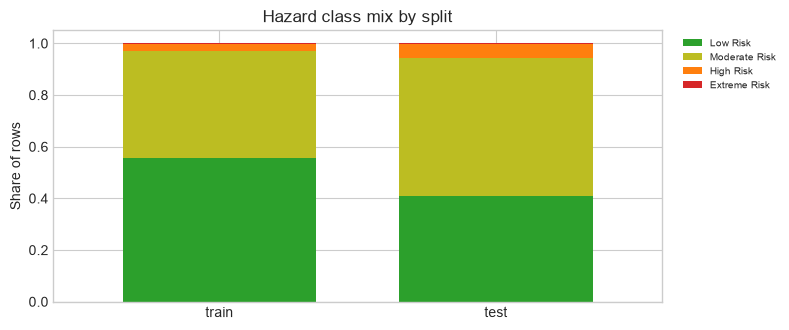

Classes with fewer than 10 rows in some split: ['Extreme Risk']. Their per-class metrics will be unstable; rely on macro F1 and the confusion matrix.


,train,test
whc_t7,,
Low Risk,5075,147
Moderate Risk,3762,191
High Risk,247,19
Extreme Risk,11,1


In [32]:
cci_splits = wx.chronological_split(cci_dataset, wx.CCI_EMBARGO)
whc_splits = wx.chronological_split(whc_dataset, wx.WHC_EMBARGO)

print("Comfort (CCI):")
display(wx.split_summary(cci_splits, wx.CCI_EMBARGO))
print("Hazard (WHC):")
display(wx.split_summary(whc_splits, wx.WHC_EMBARGO))

class_mix = pd.DataFrame({
    split: frame[WHC_TARGET].value_counts().reindex(list(wx.WHC_LABELS), fill_value=0)
    for split, frame in whc_splits.items()
}).rename(index=wx.WHC_LABELS)

fig, ax = plt.subplots(figsize=(8, 3.4))
(class_mix / class_mix.sum()).T.plot.bar(stacked=True, ax=ax, width=0.7, color=wx.WHC_COLOURS)
ax.set(title="Hazard class mix by split", ylabel="Share of rows", xlabel="")
ax.tick_params(labelrotation=0)
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
wx.save_figure(fig, "splits-class-mix", "weather_hazard")
plt.show()

rare = class_mix[(class_mix < 10).any(axis=1)]
if not rare.empty:
    print(f"Classes with fewer than 10 rows in some split: {list(rare.index)}. Their per-class "
          "metrics will be unstable; rely on macro F1 and the confusion matrix.")
class_mix

---
## 7. Leakage and serving checks

These checks are run, not assumed:

| Check | What it would catch |
|:--|:--|
| **No look-ahead** — rebuild features from hourly data cut off at 15 sample dates and compare with the full run | `center=True`, a negative shift, or any full-series transformation |
| **Serving parity** — a window of `warm-up + 5` days must reproduce the archive row exactly | Any difference between how the API and training build features |
| **Target separation** — no feature may be almost perfectly correlated with a target | A target hiding among the features |

Because the feature matrix is shared, one look-ahead check covers both tasks.

In [33]:
wx.check_no_lookahead(PIPELINE, hourly, features)
wx.check_serving_parity(PIPELINE, hourly, features, date=cci_splits["train"].index[-100])
wx.check_target_separation(cci_dataset, FEATURE_COLUMNS, CCI_TARGETS)
wx.check_target_separation(whc_dataset, FEATURE_COLUMNS, [WHC_AUX])

No look-ahead: 15 dates x 105 features unchanged after removing all later data.
Serving parity: a 35-day window reproduces the 2024-09-20 row exactly.
Target separation verified for ['cci_t1', 'cci_t2', 'cci_t3'].
Target separation verified for ['whi_t7'].


---
## 8. Outputs

Features and targets go to **separate files**, so a model can never train on a label by
forgetting to drop a column. Every file is read back after writing to confirm the rows still line
up by `feature_date`.

| File | Contents |
|:--|:--|
| `models/preprocessing/feature_pipeline.joblib` | The fitted pipeline the API loads (+ a readable `.json` description) |
| `data/interim/sydney_daily.csv` | Daily aggregates, scores and both indices (audit trail) |
| `data/processed/comfort_climate/X_{train,test}.csv` | The shared features |
| `data/processed/comfort_climate/y_{train,test}.csv` | `cci_t1`, `cci_t2`, `cci_t3` |
| `data/processed/weather_hazard/X_{train,test}.csv` | The same features, same order |
| `data/processed/weather_hazard/y_{train,test}.csv` | `whc_t7` only |
| `data/processed/weather_hazard/aux_{train,test}.csv` | `whi_t7`, error analysis only |
| `*_feature_metadata.json` | Columns, families, splits, embargo, class labels — read by `wx.load_task` |

> The comfort and hazard `X` files have the **same columns** but **not the same rows**: the 7-day
> horizon and wider embargo cost the hazard task a few days at each boundary.

In [34]:
pipeline_path = wx.save_pipeline(PIPELINE)
print(f"Pipeline -> {pipeline_path.relative_to(PATHS['root'])}\n")

shared = {
    "student_name": wx.STUDENT_NAME,
    "student_id": wx.STUDENT_ID,
    "location": {"city": "Sydney, NSW, Australia", "latitude": wx.SYDNEY.latitude,
                 "longitude": wx.SYDNEY.longitude},
    "source": "Open-Meteo Historical Weather API",
    "feature_columns": FEATURE_COLUMNS,
    "feature_groups": FEATURE_GROUPS,
    "excluded_constant_columns": builder.zero_variance_columns_,
    "warmup_days": PIPELINE.warmup_days,
    "split_boundaries": {"test_start": f"{wx.TEST_START:%Y-%m-%d}",
                         "production_cutoff": f"{wx.PRODUCTION_CUTOFF:%Y-%m-%d}"},
}

print("Comfort (CCI):")
wx.write_splits(cci_splits, OUTPUT["comfort_climate"], {"X": FEATURE_COLUMNS, "y": CCI_TARGETS})
wx.save_file({**shared, "target": "Climate Comfort Index", "prediction_type": "regression",
              "horizons_days": list(wx.CCI_HORIZONS), "target_columns": CCI_TARGETS,
              "embargo_days": wx.CCI_EMBARGO},
             OUTPUT["comfort_climate"] / "cci_feature_metadata.json")

print("\nHazard (WHC):")
wx.write_splits(whc_splits, OUTPUT["weather_hazard"],
                {"X": FEATURE_COLUMNS, "y": [WHC_TARGET], "aux": [WHC_AUX]})
wx.save_file({**shared, "target": "Weather Hazard Category",
              "prediction_type": "multiclass_classification",
              "horizons_days": [wx.WHC_HORIZON], "target_columns": [WHC_TARGET],
              "auxiliary_columns": [WHC_AUX], "embargo_days": wx.WHC_EMBARGO,
              "class_labels": {str(k): v for k, v in wx.WHC_LABELS.items()}},
             OUTPUT["weather_hazard"] / "whc_feature_metadata.json")

Pipeline -> models/preprocessing/feature_pipeline.joblib

Comfort (CCI):
  train  9,099 rows -> X_train.csv, y_train.csv
  test     362 rows -> X_test.csv, y_test.csv

Hazard (WHC):
  train  9,095 rows -> X_train.csv, y_train.csv, aux_train.csv
  test     358 rows -> X_test.csv, y_test.csv, aux_test.csv


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/data/processed/weather_hazard/whc_feature_metadata.json')

---
## 9. Summary and hand-off

**For the experiment notebooks** (`notebooks/comfort_climate/`, `notebooks/weather_hazard/`)

- Load data with `wx.load_task(...)` and `wx.load_splits(...)`; never re-split or shuffle.
- Experiment notebooks tune each model with walk-forward CV on `train`; the comparison notebook selects features for the shortlist the same way, refits the champion on all of `train`, and reads `test` **once**.
- Fit scaling and any imputation inside the model pipeline, on training data only.
- Comfort: report each horizon separately; skill should decay with lead time.
- Hazard: accuracy is not enough given the class imbalance; use macro F1 and the confusion matrix.

**For the API repository**

- Load `models/preprocessing/feature_pipeline.joblib` and call
  `wx.features_for_date(pipeline, hourly, date)`; history comes from `wx.fetch_for_serving`.
- The API needs the **same package version** that fitted the pipeline, because the saved object
  refers to classes in `nucleus_ml.weather`.
- One prediction needs at least 30 days of history before the requested date.